# การทำนายความเสี่ยงการส่งสินค้าล่าช้าในห่วงโซ่อุปทาน - Late Delivery Risk Prediction in Smart Supply Chain 🚂

**Dataset:** DataCo Smart Supply Chain

**ประเภทการเรียนรู้:** Supervised Learning — Binary Classification

**Target:** Late_delivery_risk (1 = มีความเสี่ยงล่าช้า, 0 = ไม่ล่าช้า)


**สมาชิกกลุ่ม:** โปรเจกต์กลุ่ม 5 คน (Practical Machine Learning, Thammasat University)


## 1. Problem Definition & Dataset

**คำถามวิจัย:** จากข้อมูลที่ "รู้ได้ ณ เวลาสั่งซื้อ" (ประเภทการชำระเงิน, ระดับการขนส่ง, ปลายทาง, สินค้า, ราคา, เวลาสั่ง ฯลฯ) เราสามารถทำนายได้หรือไม่ว่าออเดอร์นั้นมี ความเสี่ยงส่งล่าช้า?

**ประโยชน์:** ช่วยให้ทีมปฏิบัติการด้านโลจิสติกส์และซัพพลายเชนสามารถระบุคำสั่งซื้อที่มีความเสี่ยงส่งล่าช้าสูง ได้ล่วงหน้า ตั้งแต่รับออเดอร์ และใช้เป็นข้อมูลประกอบการตัดสินใจปรับแผนการจัดส่ง เลือกรูปแบบการขนส่งหรือแจ้งเตือนลูกค้าล่วงหน้าเพื่อลดผลกระทบและความไม่พึงพอใจ


**แหล่งข้อมูล:** https://www.kaggle.com/datasets/saicharankomati/dataco-supply-chain-dataset

**ข้อจำกัดของข้อมูลที่ต้องระวัง**
* ข้อมูลมีคอลัมน์ส่วนบุคคล (Email, Password, ชื่อ, ที่อยู่): ไม่ใช้ ในการสร้างโมเดล
* มีคอลัมน์ที่ "รู้หลังส่งของแล้ว" (เช่น Days for shipping (real), Delivery Status): เป็น Data Leakage ต้องตัดออก
* 1 ออเดอร์มีได้หลายแถว (สินค้าหลายรายการ): ต้องแบ่งข้อมูลแบบ Group

In [ ]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             ConfusionMatrixDisplay, f1_score, make_scorer, precision_score,
                             recall_score, roc_auc_score, roc_curve, classification_report)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedGroupKFold,
                                     cross_val_predict, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings('ignore') #ปิดแจ้งเตือน
sns.set_theme(style='whitegrid') #ตั้งค่าธีมกราฟของ Seaborn ให้มีพื้นหลังตารางสีขาว
RANDOM_STATE = 42 #ล็อกผลการสุ่ม
pd.set_option('display.float_format', lambda v: f'{v:,.6f}')
pd.set_option('display.max_columns', 50)


In [ ]:
GITHUB_URL = "https://raw.githubusercontent.com/Mithunvisvesh/dataco-supply-chain-analytics/main/dataset/DataCoSupplyChainDataset.csv"
LOCAL = os.environ.get("DATACO_PATH", "DataCoSupplyChainDataset.csv")
df = pd.read_csv(LOCAL, encoding='latin-1') if os.path.exists(LOCAL) else pd.read_csv(GITHUB_URL, encoding='latin-1')
print('shape:', df.shape)
df.head()

shape: (180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,...,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.000000,2,Fitness,18.251453,-66.037056,Pacific Asia,...,1/31/2018 22:56,77202,1360,13.110000,0.040000,180517,327.750000,0.290000,1,327.750000,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.000000,2,Fitness,18.279451,-66.037064,Pacific Asia,...,1/13/2018 12:27,75939,1360,16.389999,0.050000,179254,327.750000,-0.800000,1,327.750000,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,"95,125.000000",2,Fitness,37.292233,-121.881279,Pacific Asia,...,1/13/2018 12:06,75938,1360,18.030001,0.060000,179253,327.750000,-0.800000,1,327.750000,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,"90,027.000000",2,Fitness,34.125946,-118.291016,Pacific Asia,...,1/13/2018 11:45,75937,1360,22.940001,0.070000,179252,327.750000,0.080000,1,327.750000,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.000000,2,Fitness,18.253769,-66.037048,Pacific Asia,...,1/13/2018 11:24,75936,1360,29.500000,0.090000,179251,327.750000,0.450000,1,327.750000,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/15/2018 11:24,Standard Class


## 2. Data Exploration (EDA) & Leakage Check

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

In [ ]:
#missing values และแถวซ้ำ
miss = df.isna().sum().sort_values(ascending=False)
print('คอลัมน์ที่มี missing:')
display(miss[miss > 0].to_frame('missing'))  #เอาเฉพาะคอลัมน์ที่มีค่าว่างจริง ๆ มาแสดงผล

print('\nจำนวนแถวซ้ำทั้งแถว:', df.duplicated().sum())
print('จำนวนออเดอร์ที่ไม่ซ้ำ (Order Id):', df['Order Id'].nunique(), 'จากทั้งหมด', len(df), 'แถว')

คอลัมน์ที่มี missing:


,missing
Product Description,180519
Order Zipcode,155679
Customer Lname,8
Customer Zipcode,3



จำนวนแถวซ้ำทั้งแถว: 0
จำนวนออเดอร์ที่ไม่ซ้ำ (Order Id): 65752 จากทั้งหมด 180519 แถว


* Product Description ว่างทั้งคอลัมน์ และ Order Zipcode ว่างถึง 155679 ดังนั้นจึงควรตัดทิ้ง ส่วน Customer Lname และ Customer Zipcode ว่างเพียง 8 และ 3 แถว ตามลำดับ

* ข้อมูลมี 65752 ออเดอร์แต่ 180519 แถว หมายถึงหลายแถวมาจากออเดอร์เดียวกัน
ในข้อมูล Supply Chain 1 ออเดอร์ (1 Order Id) อาจมีสินค้าหลายรายการ ทำให้ 1 ออเดอร์ถูกแตกออกเป็นหลายแถว การเช็กจำนวนออเดอร์ที่ไม่ซ้ำ ช่วยให้เรารู้ว่าข้อมูลกำลังอยู่ในระดับ "รายการสินค้า (Order Item Level)" ไม่ใช่ระดับ "ใบเสร็จ (Order Level)เพราะเวลาแบ่งข้อมูลไปเทรนโมเดล เราต้องจับกลุ่มตาม Order Id เพื่อไม่ให้สินค้าจากออเดอร์เดียวกันหลุดไปอยู่ทั้งฝั่ง Train และ Test

                    count    ratio
Late_delivery_risk                
1                   98977 0.548291
0                   81542 0.451709


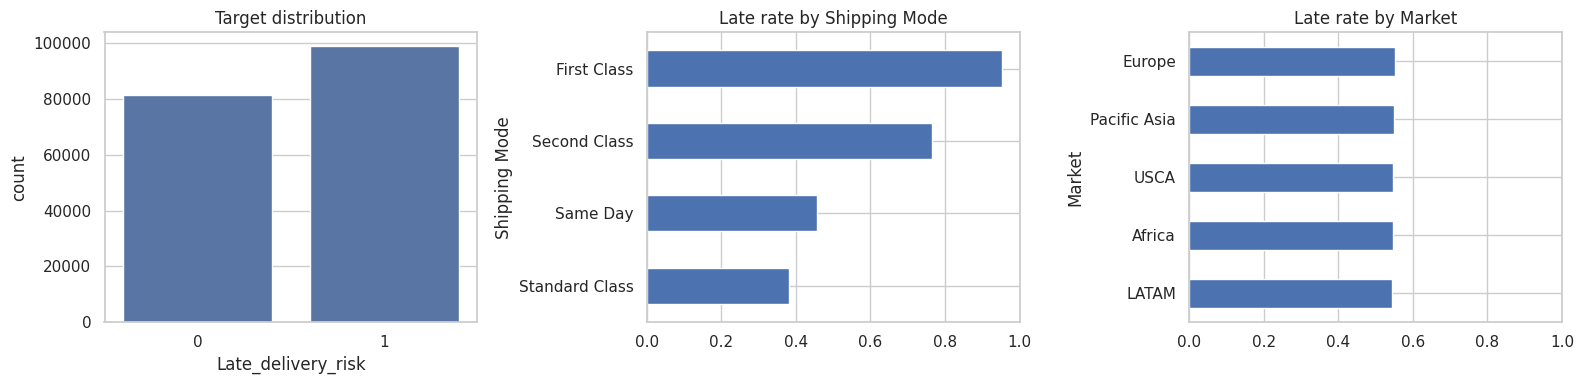

In [ ]:
#การกระจายของ Target และความสัมพันธ์กับตัวแปรสำคัญ

#นับจำนวนและคำนวณสัดส่วนของออเดอร์ที่ ส่งล่าช้า (1) เทียบกับ ส่งตรงเวลา/ล่วงหน้า (0)
print(df['Late_delivery_risk'].value_counts().rename('count').to_frame()
      .assign(ratio=lambda t: t['count'] / t['count'].sum()))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x='Late_delivery_risk', data=df, ax=ax[0]); ax[0].set_title('Target distribution')
(df.groupby('Shipping Mode')['Late_delivery_risk'].mean().sort_values()
   .plot.barh(ax=ax[1])); ax[1].set_title('Late rate by Shipping Mode'); ax[1].set_xlim(0, 1)
(df.groupby('Market')['Late_delivery_risk'].mean().sort_values()
   .plot.barh(ax=ax[2])); ax[2].set_title('Late rate by Market'); ax[2].set_xlim(0, 1)
plt.tight_layout(); plt.show()

* ข้อมูลค่อนข้างสมดุล (Balanced Dataset ~55:45) ทำให้โมเดลเรียนรู้ได้ทั้งสองกลุ่มอย่างยุติธรรม ไม่เกิดปัญหาเอียงไปทางใดทางหนึ่ง
  * ส่งล่าช้า (1): 98,977 รายการ คิดเป็น 54.83% (0.5483)   
  * ไม่ล่าช้า (0): 81,542 รายการ คิดเป็น 45.17% (0.4517)

* จากกราฟ Target distribution : แสดงกราฟแท่งเปรียบเทียบจำนวนรายการระหว่าง 0 และ 1 ให้เห็นภาพชัดเจนว่าทั้งสองคลาสมีจำนวนใกล้เคียงกัน

* จากกราฟ Late rate by Shipping Mode : เป็นอัตราการส่งช้าแยกตามรูปแบบการจัดส่ง หาเปอร์เซ็นต์การส่งล่าช้าเฉลี่ยของแต่ละประเภทการส่ง ค้นพบว่า Shipping Mode เป็นตัวแปรที่ทรงพลังมากในการทำนายผล เพราะอัตราการส่งล่าช้าแตกต่างแบบชัดเจน เนื่องจาก First Class มีอัตราส่งล่าช้าสูงถึง ~95% (เกือบทุกออเดอร์ส่งไม่ทันกำหนด), Second Class ล่าช้าสูงรองลงมาที่ ~76%, Same Day ล่าช้า ~45% และ Standard Class ล่าช้าต่ำที่สุดเพียง ~38%  

* จากกราฟ Late rate by Market : เปรียบเทียบอัตราส่งล่าช้าใน 5 ภูมิภาคหลัก (Europe, Pacific Asia, USCA, Africa, LATAM) ค้นพบว่า ทุกภูมิภาคมีอัตราส่งล่าช้าใกล้เคียงกันหมด ซึ่งหมายความว่าทำเลภูมิภาคเพียงอย่างเดียวแทบไม่มีผลต่อความเสี่ยงในการส่งล่าช้า




,count,mean,std,min,25%,50%,75%,max
Sales,"180,519.000000",203.772096,132.273077,9.990000,119.980003,199.919998,299.950012,"1,999.989990"
Product Price,"180,519.000000",141.232550,139.732492,9.990000,50.000000,59.990002,199.990005,"1,999.989990"
Order Item Quantity,"180,519.000000",2.127638,1.453451,1.000000,1.000000,1.000000,3.000000,5.000000
Order Item Discount Rate,"180,519.000000",0.101668,0.070415,0.000000,0.040000,0.100000,0.160000,0.250000
Days for shipment (scheduled),"180,519.000000",2.931847,1.374449,0.000000,2.000000,4.000000,4.000000,4.000000


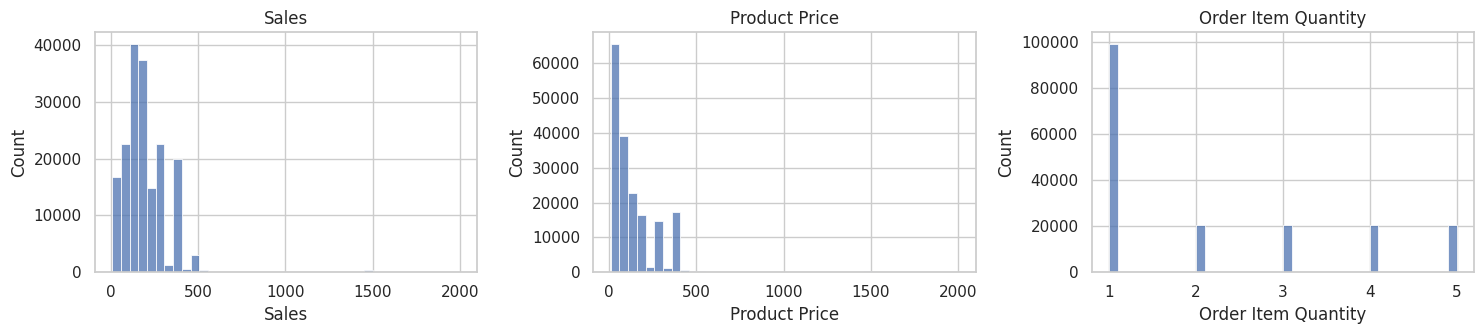

จำนวนออเดอร์ที่ Target ต่างกันภายในออเดอร์เดียว: 0
ออเดอร์ที่มีหลายแถว: 45902


In [ ]:
#ตัวแปรเชิงตัวเลข + โครงสร้างกลุ่ม (Order Id)

#คำนวณค่าสถิติพื้นฐาน
display(df[['Sales', 'Product Price', 'Order Item Quantity', 'Order Item Discount Rate',
            'Days for shipment (scheduled)']].describe().T)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, c in zip(ax, ['Sales', 'Product Price', 'Order Item Quantity']):
    sns.histplot(df[c], bins=40, ax=a); a.set_title(c)
plt.tight_layout(); plt.show()

#จับกลุ่มข้อมูลตาม Order Id เพื่อเช็กว่าสินค้าหลาย ๆ ชิ้นที่อยู่ในใบเสร็จเดียวกัน มีสถานะความเสี่ยงส่งล่าช้า (Late_delivery_risk) เหมือนกันทั้งหมดหรือไม่
n_unique = df.groupby('Order Id')['Late_delivery_risk'].nunique()
print('จำนวนออเดอร์ที่ Target ต่างกันภายในออเดอร์เดียว:', int((n_unique > 1).sum()))
print('ออเดอร์ที่มีหลายแถว:', int((df.groupby('Order Id').size() > 1).sum()))

* ข้อมูลทั้ง 5 คอลัมน์มีครบทุกแถว (180,519.0000) ไม่มีค่าว่างและไม่มีค่าติดลบที่ผิดปกติ จำนวนสินค้าต่อรายการ (Order Item Quantity) มีค่าตั้งแต่ 1 ถึง 5 ชิ้น ระยะเวลาจัดส่งตามกำหนด (Days for shipment (scheduled)) มีค่าตั้งแต่ 0 ถึง 4 วัน
* จากกราฟ Sales และ Product Price เบ้ขวา ซึ่งโมเดลต้นไม้ไม่ได้รับผลกระทบ ส่วน Logistic Regression ใช้ StandardScaler ช่วย  
Target คงที่ภายในออเดอร์เดียวกัน หมายความว่าแถวของออเดอร์เดียวกันแทบเหมือนกัน หากสุ่มแบ่ง train/test ระดับแถว แถวของออเดอร์เดียวกันจะกระจายไปทั้งสองฝั่งและทำให้ผลทดสอบ "ดีเกินจริง" จึงใช้ GroupKFold ตาม Order Id
* จากกราฟ Order Item Quantity เป็นแท่งแยกชัดเจน 5 แท่ง (1 ถึง 5 ชิ้น) โดยลูกค้าส่วนใหญ่มักสั่งซื้อครั้งละ 1 ชิ้นมากที่สุด (เกือบ 100,000 รายการ)
* จำนวนออเดอร์ที่ Target ต่างกันภายในออเดอร์เดียว = 0 หมายความว่า ยืนยันว่าสินค้าทุกชิ้นในออเดอร์เดียวกันจะส่งช้าหรือตรงเวลาพร้อมกัน 100% ส่วน ออเดอร์ที่มีหลายแถว = 45902 หมายความว่าจากออเดอร์ทั้งหมด 65752 ออเดอร์ มีถึง 45902 ออเดอร์ที่สั่งสินค้ามากกว่า 1 รายการ จึงต้องแบ่งข้อมูล Train/Test ตามกลุ่ม Order Id (StratifiedGroupKFold) เพื่อไม่ให้สินค้าจากออเดอร์เดียวกันถูกแยกไปอยู่คนละฝั่ง

In [ ]:
#พิสูจน์ Data Leakage: ถ้าใช้ "จำนวนวันที่ส่งจริง" จะทำนายได้สูงผิดปกติ แต่ข้อมูลนี้ไม่มีตอนสั่งซื้อ

#ทดลองใช้โมเดล DecisionTreeClassifier (ความลึกแค่ 3 ชั้น) ทำนายความเสี่ยงในการส่งล่าช้า
leak_cols = ['Days for shipping (real)', 'Days for shipment (scheduled)']
leak_cv = cross_validate(DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
                         df[leak_cols], df['Late_delivery_risk'], cv=3, scoring='accuracy', error_score='raise')
print(f"Accuracy เมื่อมี 'Days for shipping (real)': {leak_cv['test_score'].mean():.3f}  ")

ct = pd.crosstab(df['Delivery Status'], df['Late_delivery_risk'])
display(ct)

Accuracy เมื่อมี 'Days for shipping (real)': 0.936  


Late_delivery_risk,0,1
Delivery Status,,
Advance shipping,41592,0
Late delivery,0,98977
Shipping canceled,7754,0
Shipping on time,32196,0


* ค่าความแม่นยำ (Accuracy) สูงผิดปกติถึง 0.936 (93.6%) เพราะโมเดลแค่เอา "วันที่ส่งจริง" มาลบกับ "วันที่กำหนดไว้" ก็รู้คำตอบทันที  เนื่งจากเราต้องการทำนายความเสี่ยง ณ เวลาที่ลูกค้ากดสั่งซื้อ ซึ่งตอนนั้นสินค้ายังไม่ได้ถูกจัดส่ง เราจึงไม่มีทางรู้ Days for shipping (real) ล่วงหน้า
* หากสถานะเป็น Late delivery ค่า Late_delivery_risk จะเป็น 1 ทั้งหมด 98,977 รายการ หากสถานะเป็น Advance shipping, Shipping canceled, หรือ Shipping on time ค่า Late_delivery_risk จะเป็น 0 ทั้งหมด เนื่องจากคอลัมน์ Delivery Status คือผลลัพธ์ที่เกิดขึ้น หลังจากส่งของเสร็จสิ้นแล้ว และตรงกับคำตอบ (Target) แบบ 100% หากไม่ตัดทิ้ง โมเดลจะลอกคำตอบจากคอลัมน์นี้ตรง ๆ

**การเลือกฟีเจอร์ (Feature Selection)**


| กลุ่ม | คอลัมน์ | การจัดการ | เหตุผล |
|---|---|---|---|
| Leakage (รู้หลังส่งของ) | Days for shipping (real), Delivery Status, shipping date (DateOrders) | ตัด | Delivery Status ตรงกับ Target 100% และ Days for shipping (real) ทำให้ต้นไม้ตื้นๆ ได้ ~94% ทั้งที่ไม่มีข้อมูลนี้ตอนสั่งซื้อ |
| ผลลัพธ์หลังออเดอร์ | Order Status, Benefit per order, Order Profit Per Order, Order Item Profit Ratio, Sales per customer, Order Item Total, Order Item Discount, Order Item Product Price | ตัด | คำนวณ/เกิดขึ้นหลังออเดอร์ หรือซ้ำซ้อนกับ Sales |
| ข้อมูลส่วนบุคคล | Customer Email, Customer Fname, Customer Lname, Customer Password, Customer Street | ตัด | PII ตามข้อควรระวังของโจทย์ |
| Identifier | Customer Id, Order Item Id, Category Id, Department Id, Order Item Cardprod Id, Product Card Id, Product Category Id, Order Customer Id	 | ตัด (เก็บ Order Id เท่านั้น) | ไม่มีความหมายเชิงทำนาย / เสี่ยง overfit |
| ว่าง/ไม่มีข้อมูล | Product Description, Order Zipcode, Product Image, Product Status | ตัด | ว่างเกือบทั้งหมด / ค่าคงที่ (Product Status = 0 ทุกแถว) / เป็นลิงก์รูป |



## 3. Data Preparation

In [ ]:
# สร้างฟีเจอร์ทั้งหมด (ใช้เฉพาะข้อมูลที่รู้ ณ เวลาสั่งซื้อ)

#แปลงข้อความวันที่สั่งซื้อ (order date (DateOrders)) ให้เป็นรูปแบบวันเวลา (datetime) ของ Python พร้อมเช็กช่วงเวลาเริ่มต้น-สิ้นสุดของข้อมูล และตรวจสอบว่ามีแถวไหนแปลงไม่สำเร็จหรือไม่
dt = pd.to_datetime(df['order date (DateOrders)'], format='%m/%d/%Y %H:%M', errors='coerce')
print('ช่วงวันที่สั่งซื้อ:', dt.min(), '->', dt.max(), '| parse ไม่ได้:', int(dt.isna().sum()))

data = pd.DataFrame({
    # ฟีเจอร์ดั้งเดิม
    'Type': df['Type'],
    'Shipping Mode': df['Shipping Mode'],
    'Days for shipment (scheduled)': df['Days for shipment (scheduled)'],
    'Customer Zipcode': df['Customer Zipcode'],
    'Latitude': df['Latitude'], 'Longitude': df['Longitude'],
    'Order City': df['Order City'], 'Order State': df['Order State'], 'Order Country': df['Order Country'],
    'Product Name': df['Product Name'], 'Product Price': df['Product Price'],
    'Order Item Quantity': df['Order Item Quantity'], 'Sales': df['Sales'],
    # ฟีเจอร์เพิ่มเติมสำหรับชุด B
    'Market': df['Market'], 'Order Region': df['Order Region'].str.strip(),
    'Category Name': df['Category Name'], 'Department Name': df['Department Name'],
    'Customer Segment': df['Customer Segment'],
    'Order Item Discount Rate': df['Order Item Discount Rate'],
    'order_year': dt.dt.year, 'order_month': dt.dt.month,
    'order_dow': dt.dt.dayofweek, 'order_hour': dt.dt.hour,
})
data['is_weekend'] = (data['order_dow'] >= 5).astype(int)
y = df['Late_delivery_risk'].astype(int)
groups = df['Order Id']

# ชุดฟีเจอร์ A (encode ผ่าน Pipeline)
A_NUM = ['Days for shipment (scheduled)', 'Customer Zipcode', 'Latitude', 'Longitude',
         'Order Item Quantity', 'Sales', 'Product Price']     #numeric
A_CAT = ['Type', 'Shipping Mode', 'Order Country', 'Order City', 'Order State', 'Product Name']    #category
# ชุดฟีเจอร์ B = ตัด high-cardinality/noisy (City, State, Zipcode) เพิ่มข้อมูลสินค้า/ตลาด/เวลา/ส่วนลด
B_NUM = ['Days for shipment (scheduled)', 'Latitude', 'Longitude', 'Order Item Quantity', 'Sales',
         'Product Price', 'Order Item Discount Rate', 'order_year', 'order_month', 'order_dow',
         'order_hour', 'is_weekend']
B_CAT = ['Type', 'Shipping Mode', 'Market', 'Order Region', 'Order Country',
         'Category Name', 'Department Name', 'Customer Segment']
FEATURE_SETS = {'A': (A_NUM, A_CAT), 'B': (B_NUM, B_CAT)}
print('จำนวนฟีเจอร์ — A:', len(A_NUM) + len(A_CAT), '| B:', len(B_NUM) + len(B_CAT))

ช่วงวันที่สั่งซื้อ: 2015-01-01 00:00:00 -> 2018-01-31 23:38:00 | parse ไม่ได้: 0
จำนวนฟีเจอร์ — A: 13 | B: 20


* ต้องแยกชุด A กับชุด B ไว้แข่งกันเนื่องจาก
ในการปรับปรุงข้อมูลหรือสร้างฟีเจอร์ใหม่ เราต้องมี "เกณฑ์อ้างอิง (Baseline)"
  * ชุด A ทำหน้าที่เป็นตัวเปรียบเทียบว่า "ถ้าเอาคอลัมน์เดิม ๆ มาใช้ตามต้นฉบับ โมเดลจะได้คะแนนเท่าไหร่"
  * ชุด B ทำหน้าที่พิสูจน์ว่า "หลังจากที่เราตัดตัวแปรที่รกเกินไป (เช่น ชื่อเมือง รหัสไปรษณีย์) และเพิ่มฟีเจอร์เวลาเข้าไปใหม่ โมเดลเก่งขึ้นกว่าแบบดั้งเดิมจริงหรือไม่"
* ชุด B ตัด Order City, Order State, Product Name, Customer Zipcode ออกเนื่องจาก
  * ตัวแปรเหล่านี้มีจำนวนหมวดหมู่ย่อยเยอะมาก (High Cardinality เช่น ชื่อเมืองหลายพันเมือง ชื่อสินค้าหลายร้อยรายการ)
  * เมื่อนำไปแปลงเป็นตัวเลข (One-Hot Encoding) จะทำให้ตารางบวมมาก โมเดลจำรายละเอียดหยุมหยิมมากเกินไป (Overfitting) และประมวลผลช้า
การยุบมาใช้หมวดหมู่ระดับกลางอย่าง Order Region และ Category Name พร้อมเสริมข้อมูลเวลา (order_hour, is_weekend) จึงช่วยให้โมเดลเรียนรู้ภาพรวมได้ดีขึ้น

In [ ]:
#แบ่งข้อมูลทั้งหมดออกเป็น 5 ส่วน
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(outer.split(data, y, groups)) #ส่วนแรก เป็น Test (1 ใน 5 = 20%) ส่วน 4 ส่วนที่เหลือรวมกันเป็น Train (80%)

X_train, y_train, g_train = data.iloc[train_idx], y.iloc[train_idx], groups.iloc[train_idx]
X_test,  y_test,  g_test  = data.iloc[test_idx],  y.iloc[test_idx],  groups.iloc[test_idx]

#assert set(g_train).isdisjoint(set(g_test)) ตรวจเพื่อยืนยันว่าไม่มี Order Id ใดๆ ในชุด Train หลุดเข้าไปซ้ำในชุด Test เลยแม้แต่ออเดอร์เดียว
assert set(g_train).isdisjoint(set(g_test)), 'พบ Order Id ซ้ำระหว่าง train/test!'
print(f'Train: {len(X_train):,} แถว ({g_train.nunique():,} ออเดอร์) | late ratio = {y_train.mean():.3f}')
print(f'Test : {len(X_test):,} แถว ({g_test.nunique():,} ออเดอร์) | late ratio = {y_test.mean():.3f}')

# Validation folds (ใช้ซ้ำทุกการทดลอง)
inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv = list(inner.split(X_train, y_train, g_train))
print('จำนวน fold:', len(cv))

Train: 144,543 แถว (52,602 ออเดอร์) | late ratio = 0.549
Test : 35,976 แถว (13,150 ออเดอร์) | late ratio = 0.546
จำนวน fold: 5


**การแบ่งข้อมูล (Train / Validation / Test) และการป้องกัน Leakage**
* Test set 20% แยกออกตั้งแต่ต้นด้วย StratifiedGroupKFold (คง สัดส่วน Target และแบ่งตาม Order Id)
* Train 80% ใช้ StratifiedGroupKFold 5-fold เป็น Validation สำหรับเปรียบเทียบโมเดล จูนพารามิเตอร์ และเลือก threshold
* การ encode/scale อยู่ใน Pipeline จึง fit เฉพาะข้อมูลฝึกของแต่ละ fold (ไม่รั่วไหล)

In [ ]:
#เตรียมข้อมูลสำหรับ Logistic Regression
def make_linear_pre(num, cat):
    return ColumnTransformer([    #แยกคอลัมน์ไปทำคนละอย่าง แล้วเอาผลมาต่อกัน
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num),    #แทนค่าว่าง (NaN) ด้วย มัธยฐานของคอลัมน์นั้น ในชุด A คอลัมน์ที่มีค่าว่างคือ Customer Zipcode
        ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=100), cat),
    ])

#เตรียมข้อมูลสำหรับ Random Forest
def make_tree_pre(num, cat):
    return ColumnTransformer([
        ('num', SimpleImputer(strategy='median'), num),
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1,
                               encoded_missing_value=-1, min_frequency=100), cat),
    ])

* Missing Values : แทนค่าว่าง (NaN) ด้วย มัธยฐานของคอลัมน์นั้น ในชุด A คอลัมน์ที่มีค่าว่างคือ Customer Zipcode
* Feature Scaling : StandardScaler
* Encoding : โมเดลเชิงเส้นใช้ One-Hot + StandardScaler ส่วนโมเดลต้นไม้ใช้ OrdinalEncoder

## 4. Pipeline, Baseline และการเปรียบเทียบโมเดล

**แนวทางที่เปรียบเทียบ**
| โมเดล | บทบาท | เหตุผล |
|---|---|---|
| DummyClassifier | Baseline ต่ำสุด | วัดว่าการ "เดาตาม prior" ได้เท่าไร |
| Logistic Regression (Shipping Mode อย่างเดียว) | Baseline เชิงกฎ | ดูว่าฟีเจอร์เดียวอธิบายได้เท่าไร (จาก EDA Shipping Mode สัมพันธ์กับ Target สูง) |
| Logistic Regression (ทุกฟีเจอร์) | Baseline เชิงเส้น | โมเดลง่าย ตีความได้ |
| Random Forest | โมเดลที่ไม่เป็นเชิงเส้น (bagging) | จับ interaction ได้ ทนต่อ outlier |
| HistGradientBoosting | โมเดลที่ไม่เป็นเชิงเส้น (boosting) | เรียนรู้จากข้อผิดพลาดของต้นก่อนหน้า จับ interaction ได้ แม่นยำสูง |


In [ ]:
#ประกอบโมเดล
def make_model(kind, fs='A', **params):
    num, cat = FEATURE_SETS[fs]
    if kind == 'dummy':
        return Pipeline([('pre', make_tree_pre(num, cat)), ('clf', DummyClassifier(strategy='prior'))])
    if kind == 'logreg':
        return Pipeline([('pre', make_linear_pre(num, cat)),
                         ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, **params))])
    if kind == 'rf':
        p = dict(n_estimators=100, min_samples_leaf=20, max_features='sqrt', n_jobs=-1,
                 random_state=RANDOM_STATE); p.update(params)
        return Pipeline([('pre', make_tree_pre(num, cat)), ('clf', RandomForestClassifier(**p))])
    if kind == 'hgb':
        p = dict(max_iter=100, random_state=RANDOM_STATE); p.update(params)
        return Pipeline([('pre', make_tree_pre(num, cat)), ('clf', HistGradientBoostingClassifier(**p))])
    raise ValueError(kind)

SCORING = {
    'roc_auc': 'roc_auc',
    'f1_macro': 'f1_macro',
    'bal_acc': 'balanced_accuracy',
    'prec_late': make_scorer(precision_score, zero_division=0),
    'rec_late': make_scorer(recall_score, zero_division=0),
}
cv_rows, registry = [], {}   # registry เก็บโมเดล (ยังไม่ fit) ไว้ใช้ตอนทดสอบ

def run_cv(name, model, fs):
    num, cat = FEATURE_SETS[fs]
    t0 = time.time()
    res = cross_validate(model, X_train[num + cat], y_train, cv=cv, scoring=SCORING, n_jobs=1)
    row = {'model': name, 'features': fs}
    for k in SCORING:
        row[k] = res['test_' + k].mean(); row[k + '_sd'] = res['test_' + k].std()
    row['fit_s'] = (time.time() - t0) / len(cv)
    cv_rows.append(row); registry[name] = (model, fs)
    import sys; print(f'  [cv] {name}: {time.time()-t0:.0f}s', file=sys.stderr, flush=True)
    return row

def show_cv(names=None):
    t = pd.DataFrame(cv_rows)
    if names is not None: t = t[t['model'].isin(names)]
    t = t.assign(**{c: t[c].map('{:.4f}'.format) + ' ±' + t[c + '_sd'].map('{:.4f}'.format)
                    for c in SCORING})
    cols = ['model', 'features'] + list(SCORING) + ['fit_s']
    display(t[cols].set_index('model'))

In [ ]:
# Baseline + การเปรียบเทียบ (ฟีเจอร์ชุด A, 5-fold Group CV)
# Baseline เชิงกฎ: ใช้ Shipping Mode ฟีเจอร์เดียว
FEATURE_SETS['SM'] = ([], ['Shipping Mode'])

run_cv('Dummy (prior)',               make_model('dummy', 'SM'),  'SM')
run_cv('LogReg: Shipping Mode only',  make_model('logreg', 'SM'), 'SM')
run_cv('LogReg (A)',                  make_model('logreg', 'A'),  'A')
run_cv('RandomForest (A)',            make_model('rf', 'A'),      'A')
run_cv('HistGB default (A)',          make_model('hgb', 'A'),     'A')
show_cv()

  [cv] Dummy (prior): 1s
  [cv] LogReg: Shipping Mode only: 2s
  [cv] LogReg (A): 20s
  [cv] RandomForest (A): 102s
  [cv] HistGB default (A): 28s


,features,roc_auc,f1_macro,bal_acc,prec_late,rec_late,fit_s
model,,,,,,,
Dummy (prior),SM,0.5000 ±0.0000,0.3543 ±0.0029,0.5000 ±0.0000,0.5488 ±0.0070,1.0000 ±0.0000,0.210852
LogReg: Shipping Mode only,SM,0.7264 ±0.0059,0.6898 ±0.0058,0.7098 ±0.0054,0.8472 ±0.0064,0.5377 ±0.0072,0.491252
LogReg (A),A,0.7334 ±0.0058,0.6857 ±0.0034,0.6983 ±0.0025,0.7950 ±0.0039,0.5779 ±0.0076,3.960725
RandomForest (A),A,0.7312 ±0.0038,0.6861 ±0.0049,0.6995 ±0.0039,0.8000 ±0.0027,0.5734 ±0.0074,20.386812
HistGB default (A),A,0.7346 ±0.0044,0.6895 ±0.0047,0.7053 ±0.0040,0.8192 ±0.0043,0.5614 ±0.0072,5.553343


**วิเคราะห์ผล Baseline vs โมเดลอื่น**
**ผลจาก 5-fold Group CV (ค่าเฉลี่ย ± SD):**
1. Dummy (baseline ต่ำสุด)
    * ROC_AUC = 0.5000 และ SD = 0 หมายถึงไม่มีความสามารถแยกคลาสเลย
    * recall = 1.0 ไม่ได้แปลว่าดี Dummy ทำนาย "ล่าช้า" ทุกแถว (คลาสส่วนใหญ่) จึงจับได้ครบทุกรายที่ล่าช้า แต่ทำนายผิดทุกรายที่ไม่ล่าช้า
    * precision = 0.5488 เท่ากับสัดส่วนล่าช้าในข้อมูล (54.83%) พอดี
    * F1-macro = 0.3543 ต่ำมาก เพราะ F1 ของคลาส "ไม่ล่าช้า" เป็น 0
2. LogReg: Shipping Mode only (baseline ฟีเจอร์เดียว)
    * ROC_AUC = 0.7264 กระโดดจาก 0.50 มาก แปลว่าฟีเจอร์เดียวให้สัญญาณเกือบทั้งหมด
    * precision สูงสุดในตาราง (0.8472) แต่ recall ต่ำสุดในกลุ่มที่ไม่ใช่ Dummy (0.5377) เหตุผลที่อนุมานได้คือโมเดลมีผลทำนายแค่ 4 ค่า (ตาม 4 Shipping Mode) เมื่อตัดที่ 0.5 จะเตือนเฉพาะโหมดที่อัตราล่าช้าเกิน 50% (First Class ~95%, Second Class ~76%) ซึ่งเตือนแล้วถูกบ่อย แต่ไปพลาดออเดอร์ล่าช้าใน Standard Class และ Same Day
3. โมเดลที่ใช้ชุด A (13 ฟีเจอร์)
    * ROC_AUC อยู่ระหว่าง 0.7312–0.7346 ต่างจาก baseline ฟีเจอร์เดียวเพียง 0.005–0.008
    * ขณะที่ SD ของ AUC อยู่ที่ 0.0038–0.0058 ผลต่างจึงอยู่ในระดับเดียวกับความแกว่งระหว่าง fold ยืนยันไม่ได้ว่าโมเดลซับซ้อนดีกว่าจริง
    * F1-macro และ bal_acc ของ LogReg/RF ต่ำกว่า baseline ฟีเจอร์เดียวเล็กน้อย (F1 0.6857/0.6861 เทียบกับ 0.6898) การเพิ่มฟีเจอร์เมือง/รัฐ/ZIP/สินค้าไม่ช่วย และอาจเพิ่ม noise
    * HistGB ดีที่สุดเล็กน้อยทั้ง AUC (0.7346) และ bal_acc (0.7053) แต่ F1-macro (0.6895) เท่ากับ baseline ฟีเจอร์เดียว (0.6898)

## 5. Model Improvement Experiments

ทุกการทดลองใช้ CV folds เดียวกัน และไม่ใช้ Test Set ในการตัดสินใจ

### Experiment 1 — Feature Engineering / Selection (ชุด A → ชุด B)
สมมติฐาน: ฟีเจอร์ Order City (3,597 ค่า), Order State (1,089 ค่า), Customer Zipcode เป็น high-cardinality ที่น่าจะ noisy ส่วนข้อมูลสินค้า/ตลาด/เวลาสั่ง/ส่วนลดอาจมีสัญญาณที่เป็นประโยชน์กว่า

In [ ]:
run_cv('LogReg (B)',        make_model('logreg', 'B'), 'B')
run_cv('RandomForest (B)',  make_model('rf', 'B'),     'B')
run_cv('HistGB default (B)', make_model('hgb', 'B'),   'B')

exp1 = ['LogReg (A)', 'LogReg (B)', 'RandomForest (A)', 'RandomForest (B)',
        'HistGB default (A)', 'HistGB default (B)']
show_cv(exp1)

# เลือกชุดฟีเจอร์จาก ROC-AUC (CV) ของ HGB เป็นหลัก
t = pd.DataFrame(cv_rows).set_index('model')
BEST_FS = 'B' if t.loc['HistGB default (B)', 'roc_auc'] >= t.loc['HistGB default (A)', 'roc_auc'] else 'A'
print('ชุดฟีเจอร์ที่เลือกสำหรับการทดลองต่อไป:', BEST_FS)

  [cv] LogReg (B): 17s
  [cv] RandomForest (B): 104s
  [cv] HistGB default (B): 22s


,features,roc_auc,f1_macro,bal_acc,prec_late,rec_late,fit_s
model,,,,,,,
LogReg (A),A,0.7334 ±0.0058,0.6857 ±0.0034,0.6983 ±0.0025,0.7950 ±0.0039,0.5779 ±0.0076,3.960725
RandomForest (A),A,0.7312 ±0.0038,0.6861 ±0.0049,0.6995 ±0.0039,0.8000 ±0.0027,0.5734 ±0.0074,20.386812
HistGB default (A),A,0.7346 ±0.0044,0.6895 ±0.0047,0.7053 ±0.0040,0.8192 ±0.0043,0.5614 ±0.0072,5.553343
LogReg (B),B,0.7399 ±0.0034,0.7004 ±0.0049,0.7168 ±0.0044,0.8372 ±0.0045,0.5679 ±0.0062,3.493346
RandomForest (B),B,0.7637 ±0.0050,0.7134 ±0.0067,0.7287 ±0.0061,0.8464 ±0.0060,0.5869 ±0.0079,20.879452
HistGB default (B),B,0.7665 ±0.0033,0.7130 ±0.0065,0.7283 ±0.0060,0.8460 ±0.0066,0.5864 ±0.0065,4.382383


ชุดฟีเจอร์ที่เลือกสำหรับการทดลองต่อไป: B


**Experiment 1 — Feature Engineering / Selection (ชุด A → ชุด B)**

เมื่อตัด high-cardinality ออก พบว่าทุกโมเดลมีค่าดีขึ้น ดังนี้
* ความแม่นยำ : โมเดลตระกูลต้นไม้อย่าง RandomForest และ HistGB default ได้รับประโยชน์จากชุดฟีเจอร์ B มากที่สุด โดย   
  * RandomForest มีค่า roc_auc เพิ่มจาก 0.7312 เป็น 0.7637 (+0.0325)   
  * HistGB default มีค่า roc_auc เพิ่มจาก 0.7346 เป็น 0.7665 (+0.0319)   
  
  ในขณะที่ LogReg มีค่า roc_auc เพิ่มจาก 0.7334 เป็น 0.7399 มีค่าเปลี่ยนแปลงเพียง +0.0065 เมื่อเทียบกับโมเดลตระกูลต้นไม้   
  
* ความเสถียร : ค่าส่วนเบี่ยงเบนมาตรฐานของ LogReg (ลดจาก ±0.0058 เหลือ ±0.0034) และ HistGB default (ลดจาก ±0.0044 เหลือ ±0.0033) บนชุด B ลดลงจากชุด A แสดงว่าผลลัพธ์ของโมเดลหลักนิ่งขึ้นข้ามแต่ละ Fold (ส่วน RandomForest เพิ่มขึ้นเล็กน้อยจาก ±0.0038 เป็น ±0.0050)   
* การประมวลผล (fit_s): HistGB default (B) ให้ประสิทธิภาพ ROC-AUC สูงที่สุดในกลุ่มที่เปรียบเทียบ โดยใช้เวลาฝึกต่อ Fold น้อยมาก เร็วกว่า RandomForest (B) อย่างชัดเจน และช้ากว่า LogReg (B) เพียงเล็กน้อย
* Trade-off of recall: ใน HistGB default (B) precision ของคลาส late อยู่ที่ 0.846 ส่วน recall 0.5864 แปลว่าเมื่อโมเดลทายว่า "ล่าช้า" มักถูก ~85% แต่ยังตกหล่นคลาสล่าช้าจริงไปราว 41% (1-0.5864) ซึ่งอาจปรับได้ด้วยการเลื่อน threshold
* **สรุป** : BEST_FS = B เพราะ HistGB default (B) ได้ ROC-AUC 0.7665 สูงกว่า HistGB default (A) ที่ 0.7346 จึงใช้ชุดฟีเจอร์ B ต่อ

### Experiment 2 — Hyperparameter Tuning (HistGradientBoosting)
ใช้ RandomizedSearchCV (15 ชุดพารามิเตอร์ × 5-fold Group CV บนข้อมูลฝึกเท่านั้น) เลือกจาก ROC-AUC

In [ ]:
param_dist = {
    'clf__learning_rate': loguniform(0.02, 0.3),
    'clf__max_iter': [100, 200, 300],
    'clf__max_leaf_nodes': [15, 31, 63],
    'clf__max_depth': [None, 4, 6, 8],
    'clf__min_samples_leaf': [20, 50, 100, 200],
    'clf__l2_regularization': loguniform(1e-3, 10),
}
num, cat = FEATURE_SETS[BEST_FS]
search = RandomizedSearchCV(make_model('hgb', BEST_FS), param_dist, n_iter=15, cv=cv, scoring='roc_auc',
                            random_state=RANDOM_STATE, n_jobs=1, refit=True)
t0 = time.time()
search.fit(X_train[num + cat], y_train)
print(f'ใช้เวลา {time.time()-t0:.0f} วินาที')
print('พารามิเตอร์ที่ดีที่สุด:')
for k, v in search.best_params_.items(): print(f'  {k}: {v}')

res = pd.DataFrame(search.cv_results_).sort_values('rank_test_score')
display(res[['rank_test_score', 'mean_test_score', 'std_test_score']].head(5))

best_params = {k.replace('clf__', ''): v for k, v in search.best_params_.items()}
run_cv(f'HistGB tuned ({BEST_FS})', make_model('hgb', BEST_FS, **best_params), BEST_FS)
show_cv(['HistGB default (A)', f'HistGB default ({BEST_FS})', f'HistGB tuned ({BEST_FS})'])

ใช้เวลา 424 วินาที
พารามิเตอร์ที่ดีที่สุด:
  clf__l2_regularization: 0.06071989493441298
  clf__learning_rate: 0.02621860739064525
  clf__max_depth: 6
  clf__max_iter: 100
  clf__max_leaf_nodes: 63
  clf__min_samples_leaf: 50


,rank_test_score,mean_test_score,std_test_score
1,1,0.768337,0.004289
10,2,0.768175,0.004451
8,3,0.768006,0.004609
7,4,0.767934,0.005058
3,5,0.766325,0.004855


  [cv] HistGB tuned (B): 25s


,features,roc_auc,f1_macro,bal_acc,prec_late,rec_late,fit_s
model,,,,,,,
HistGB default (A),A,0.7346 ±0.0044,0.6895 ±0.0047,0.7053 ±0.0040,0.8192 ±0.0043,0.5614 ±0.0072,5.553343
HistGB default (B),B,0.7665 ±0.0033,0.7130 ±0.0065,0.7283 ±0.0060,0.8460 ±0.0066,0.5864 ±0.0065,4.382383
HistGB tuned (B),B,0.7683 ±0.0043,0.7149 ±0.0067,0.7309 ±0.0061,0.8532 ±0.0060,0.5840 ±0.0075,5.067495


**Experiment 2 — Hyperparameter Tuning**
* Best parameter : จากการทดลอง พบว่า ได้ learning rate ต่ำ ที่ 0.026 คู่กับ max_iter = 100 ทำให้โมเดลเรียนรู้ช้าและหยุดเร็ว จึงเป็นโมเดลที่ ค่อนข้าง regularize แรง น่าจะเป็นเพราะมีสัญญาณจริงในข้อมูลไม่แรงมาก (ROC-AUC ~0.77) การเพิ่มความซับซ้อนจึงไม่ช่วย และเนื่องจากค่าพารามิเตอร์อยู่ติดขอบล่างของช่วงที่ตั้งไว้ (0.02 และ 100) จึงอาจมีค่าที่ดีกว่าอยู่นอกช่วง
* Top 5 จากการ Search : ชุดพารามิเตอร์อันดับ 1 ถึง 4 มีคะแนน mean_test_score เกาะกลุ่มกันแน่นมากในช่วง 0.767934 ถึง 0.768337 แสดงว่าโครงสร้างโมเดลบนชุดฟีเจอร์ B ค่อนข้างเสถียร
* ตารางเปรียบเทียบก่อนและหลังการปรับจูน : Tuning ช่วยได้ค่อนข้างน้อย ค่า ROC-AUC เพิ่มจาก 0.7665 เป็น 0.7683 (+0.0018) ซึ่งเล็กกว่าความผันผวนของผลลัพธ์ในแต่ละ fold (±0.003–0.004) จึงบอกไม่ได้ว่าดีขึ้นจริงหรือแค่บังเอิญ
* **สรุป** : เมื่อเทียบกับ Experiment 1 การเลือกฟีเจอร์ช่วยเพิ่ม ROC-AUC +0.032 ซึ่งมากกว่า tuning (+0.0018) ราว 18 เท่า แสดงว่าคุณภาพฟีเจอร์สำคัญกว่าการปรับพารามิเตอร์

### Experiment 3 — Imbalance Handling และ Threshold Tuning
Target ไม่ได้ไม่สมดุลมาก (~55/45) จึงทดสอบว่าการถ่วงน้ำหนักคลาส (class_weight='balanced') และการปรับ decision threshold ช่วยให้ Recall ของคลาส "ล่าช้า" ดีขึ้นโดยไม่ทำให้ Precision ตกมากหรือไม่  
Threshold ถูกเลือกจาก out-of-fold predictions บนข้อมูลฝึก (ไม่ใช้ Test)

  [cv] HistGB tuned+balanced (B): 26s


,threshold,accuracy,bal_acc,prec_late,rec_late,f1_late,f1_macro
variant,,,,,,,
HistGB tuned (B) @0.50,0.500000,0.716576,0.730909,0.853225,0.584005,0.693400,0.714947
HistGB tuned (B) @0.53 (tuned),0.530000,0.716666,0.731081,0.854121,0.583336,0.693224,0.715002
HistGB tuned+balanced (B) @0.50,0.500000,0.716596,0.731041,0.854316,0.582996,0.693048,0.714919
HistGB tuned+balanced (B) @0.46 (tuned),0.460000,0.716666,0.731036,0.853690,0.583753,0.693375,0.715021


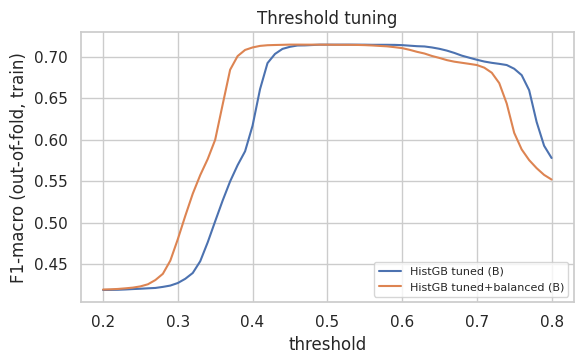

In [ ]:
tuned_name = f'HistGB tuned ({BEST_FS})'
bal_name = f'HistGB tuned+balanced ({BEST_FS})'
run_cv(bal_name, make_model('hgb', BEST_FS, class_weight='balanced', **best_params), BEST_FS)

Xtr = X_train[num + cat]
oof = {}
for nm in [tuned_name, bal_name]:
    oof[nm] = cross_val_predict(clone(registry[nm][0]), Xtr, y_train, cv=cv, method='predict_proba', n_jobs=1)[:, 1]

def metrics_at(y_true, proba, thr):
    pred = (proba >= thr).astype(int)
    return {'threshold': thr, 'accuracy': accuracy_score(y_true, pred),
            'bal_acc': balanced_accuracy_score(y_true, pred),
            'prec_late': precision_score(y_true, pred, zero_division=0),
            'rec_late': recall_score(y_true, pred), 'f1_late': f1_score(y_true, pred),
            'f1_macro': f1_score(y_true, pred, average='macro')}

grid = np.round(np.arange(0.20, 0.801, 0.01), 2)
thr_rows, best_thr = [], {}
for nm, p in oof.items():
    best_thr[nm] = max(grid, key=lambda th: f1_score(y_train, (p >= th).astype(int), average='macro'))
    thr_rows.append({'variant': nm + ' @0.50', **metrics_at(y_train, p, 0.5)})
    thr_rows.append({'variant': nm + f' @{best_thr[nm]:.2f} (tuned)', **metrics_at(y_train, p, best_thr[nm])})
display(pd.DataFrame(thr_rows).set_index('variant'))

fig, ax = plt.subplots(figsize=(6, 3.8))
for nm, p in oof.items():
    ax.plot(grid, [f1_score(y_train, (p >= th).astype(int), average='macro') for th in grid], label=nm)
ax.set_xlabel('threshold'); ax.set_ylabel('F1-macro (out-of-fold, train)'); ax.legend(fontsize=8)
ax.set_title('Threshold tuning'); plt.tight_layout(); plt.show()

**Experiment 3 — Imbalance Handling และ Threshold Tuning**
* ตารางเปรียบเทียบผลลัพธ์ (Out-of-fold บนชุด Train) : ผลลัพธ์ของทั้ง 4 รูปแบบ แทบไม่แตกต่างกันเลย โดยค่า f1_macro เกาะกลุ่มอยู่ที่ 0.7149 – 0.7150 และ accuracy อยู่ที่ประมาณ 0.7166 – 0.7167 เท่า ๆ กัน เนื่องจาก สัดส่วนข้อมูลเป้าหมายเดิมค่อนข้างสมดุลอยู่แล้ว การเพิ่ม class_weight='balanced' จึงเป็นเพียงการเลื่อนสเกลความน่าจะเป็นให้ต่ำลง แต่ไม่ได้เปลี่ยนความสามารถในการจำแนกของโมเดล
* Threshold tuning : F1-macro ไม่ไวต่อ threshold ในช่วงกว้าง (0.45–0.60) การเลื่อน threshold และการใช้ class_weight='balanced' จึงไม่ทำให้ผลดีขึ้น เพราะแค่สลับ precision กับ recall บนเส้นโค้งเดิม ไม่ได้ทำให้โมเดลแยกคลาสได้ดีขึ้น และ threshold 0.50 อยู่ในช่วงยอดราบ
* **สรุป** : class_weight='balanced' และการปรับ threshold ไม่ช่วยให้ผลดีขึ้น (F1-macro ≈ 0.715 เท่าเดิม, recall ของคลาส late ยัง ~0.58) จึงใช้ HistGB tuned (B) ที่ threshold 0.50 ต่อได้

## 6. การเลือกโมเดลสุดท้าย (ตัดสินจาก Validation/CV เท่านั้น)

In [ ]:
cv_df = pd.DataFrame(cv_rows).set_index('model')
display(cv_df[['features', 'roc_auc', 'roc_auc_sd', 'f1_macro', 'bal_acc', 'prec_late', 'rec_late']]
        .sort_values('roc_auc', ascending=False))

# กติกาเลือก: โมเดลที่ได้ ROC-AUC (CV) สูงสุด; ถ้าห่างกันไม่เกิน 1 SD ให้เลือกตัวที่ง่าย/เร็วกว่า (fit_s ต่ำกว่า)
eligible = cv_df.drop(index=['Dummy (prior)', 'LogReg: Shipping Mode only'])
top = eligible['roc_auc'].max(); sd = eligible.loc[eligible['roc_auc'].idxmax(), 'roc_auc_sd']
near_top = eligible[eligible['roc_auc'] >= top - sd]
FINAL_NAME = near_top['fit_s'].idxmin()
print('ผู้เข้าใกล้อันดับ 1 (ภายใน 1 SD):', list(near_top.index))
print('>>> โมเดลสุดท้ายที่เลือกจาก CV:', FINAL_NAME)

,features,roc_auc,roc_auc_sd,f1_macro,bal_acc,prec_late,rec_late
model,,,,,,,
HistGB tuned (B),B,0.768337,0.004289,0.714892,0.730863,0.853181,0.583976
HistGB tuned+balanced (B),B,0.768179,0.004066,0.714862,0.730991,0.854277,0.582963
HistGB default (B),B,0.766455,0.003330,0.712990,0.728274,0.846018,0.586420
RandomForest (B),B,0.763674,0.005050,0.713378,0.728658,0.846374,0.586875
LogReg (B),B,0.739879,0.003438,0.700408,0.716807,0.837230,0.567940
HistGB default (A),A,0.734552,0.004408,0.689522,0.705340,0.819154,0.561397
LogReg (A),A,0.733430,0.005819,0.685678,0.698308,0.794969,0.577926
RandomForest (A),A,0.731232,0.003764,0.686137,0.699511,0.799995,0.573404
LogReg: Shipping Mode only,SM,0.726381,0.005898,0.689752,0.709841,0.847172,0.537683


ผู้เข้าใกล้อันดับ 1 (ภายใน 1 SD): ['HistGB default (B)', 'HistGB tuned (B)', 'HistGB tuned+balanced (B)']
>>> โมเดลสุดท้ายที่เลือกจาก CV: HistGB default (B)


**สรุปการเลือกโมเดลสุดท้าย**
* ชุดฟีเจอร์ B ชนะ A ชัดเจน : โมเดลชุด B ทั้ง 5 ตัวอยู่อันดับ 1–5 ที่ ROC-AUC 0.74–0.77 ส่วนชุด A อยู่ที่ 0.731–0.735 ยืนยันผล Experiment 1
* 1-SD Cutoff (ถ้าต่างกันไม่เกินความผันผวน ให้ถือว่าเท่ากัน แล้วเลือกตัวที่ง่ายหรือเร็วกว่า) :
  * คำนวณ: อันดับ 1 คือ HistGB tuned (B) ทำคะแนน roc_auc สูงสุดที่ 0.768337 โดยมีค่า roc_auc_sd เท่ากับ 0.004289
  
    ดังนั้น เกณฑ์ขั้นต่ำ (top - sd) จะได้ 0.768337 - 0.004289 = 0.764048
  * โมเดลที่ผ่านเกณฑ์ : HistGB ทั้ง 3 รูปแบบผ่านเกณฑ์ เพราะคะแนนสูงกว่าเส้นตัด ที่ 0.764048 ได้แก่ tuned (B) ที่ 0.768337, tuned+balanced (B) ที่ 0.768179 และ default (B) ที่ 0.766455 ซึ่งต่ำกว่าอันดับ 1 เพียง 0.0019 เล็กกว่า SD (0.004289) ในขณะที่ RandomForest (B) ได้ 0.763674 ต่ำกว่าเส้นตัดเล็กน้อย จึงไม่ผ่านเกณฑ์
* **สรุป** : เลือก HistGB default (B) เพราะคะแนนต่างจากอันดับ 1 เพียง 0.0019 (เล็กกว่า SD 0.004289) และเป็นตัวที่ fit เร็วที่สุดในกลุ่ม จึงเลือกตัวที่เรียบง่ายและเร็วกว่าแทนที่จะเลือกตัวที่คะแนนสูงกว่าเพียงเล็กน้อย

## 7. การประเมินบน Test Set (ใช้ครั้งเดียวหลังเลือกโมเดลแล้ว)

In [ ]:
def fit_predict(name):
    model, fs = registry[name]
    n_, c_ = FEATURE_SETS[fs]
    m = clone(model).fit(X_train[n_ + c_], y_train)
    return m, m.predict_proba(X_test[n_ + c_])[:, 1]

# ใช้ Test Set กับโมเดลสุดท้ายที่เลือกจาก CV (ข้อ 6) ตัวเดียวเท่านั้น
FINAL_THR = best_thr.get(FINAL_NAME, 0.5)
fitted, test_proba = {}, {}
fitted[FINAL_NAME], test_proba[FINAL_NAME] = fit_predict(FINAL_NAME)

def test_metrics(name, thr=0.5):
    p = test_proba[name]
    return {'model': name, **metrics_at(y_test, p, thr),
            'roc_auc': roc_auc_score(y_test, p), 'pr_auc': average_precision_score(y_test, p)}

test_df = pd.DataFrame([test_metrics(FINAL_NAME, FINAL_THR)]).set_index('model')
display(test_df[['threshold', 'accuracy', 'bal_acc', 'prec_late', 'rec_late', 'f1_late', 'f1_macro', 'roc_auc', 'pr_auc']])


,threshold,accuracy,bal_acc,prec_late,rec_late,f1_late,f1_macro,roc_auc,pr_auc
model,,,,,,,,,
HistGB default (B),0.500000,0.724511,0.737346,0.853186,0.598759,0.703680,0.723143,0.774359,0.838438


* ไม่พบสัญญาณ overfit: HistGB default (B) ได้ ROC-AUC 0.7744 บน Test ใกล้เคียงและสูงกว่า CV ที่ 0.7665 เล็กน้อย
* ทุกตัวชี้วัดอยู่ในระดับใกล้กันและ PR-AUC 0.838 สูงกว่าสัดส่วนคลาส late (~0.55) ชัดเจน
* เลือกใช้ threshold 0.50 เพราะ Experiment 3 พบว่าการปรับ threshold และ class_weight ไม่ช่วยให้ดีขึ้น
* precision ของคลาส late สูง (0.853) แต่ recall ยังอยู่ที่ ~0.60 อาจจะต้องแก้ด้วยฟีเจอร์ที่แยกคลาสได้ดีขึ้น ไม่ใช่การปรับโมเดล

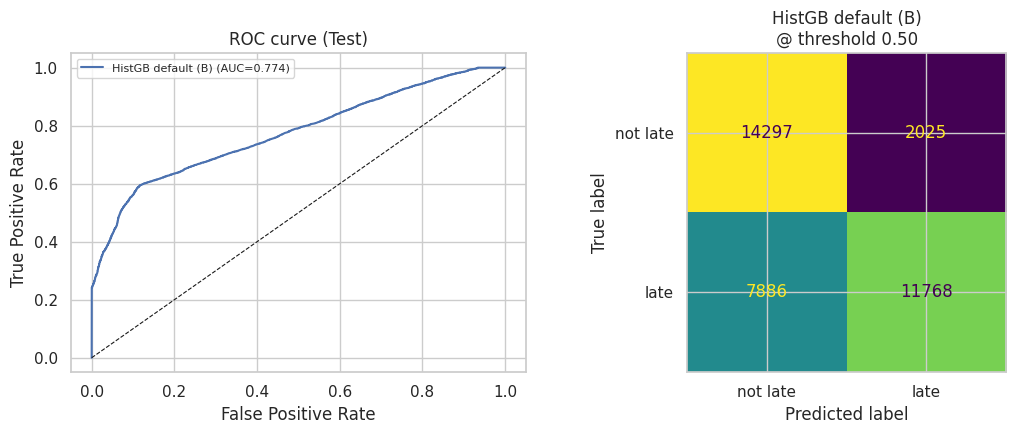

Classification report — HistGB default (B) @ 0.50
              precision    recall  f1-score   support

no late risk      0.645     0.876     0.743     16322
   late risk      0.853     0.599     0.704     19654

    accuracy                          0.725     35976
   macro avg      0.749     0.737     0.723     35976
weighted avg      0.759     0.725     0.721     35976



In [ ]:
# ROC curve + Confusion Matrix ของโมเดลสุดท้าย (Test Set)
final_model, final_proba = fitted[FINAL_NAME], test_proba[FINAL_NAME]
final_pred = (final_proba >= FINAL_THR).astype(int)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
fpr, tpr, _ = roc_curve(y_test, final_proba)
ax[0].plot(fpr, tpr, label=f'{FINAL_NAME} (AUC={roc_auc_score(y_test, final_proba):.3f})')
ax[0].plot([0, 1], [0, 1], 'k--', lw=0.8); ax[0].legend(fontsize=8); ax[0].set_title('ROC curve (Test)')
ax[0].set_xlabel('False Positive Rate'); ax[0].set_ylabel('True Positive Rate')

ConfusionMatrixDisplay.from_predictions(y_test, final_pred, display_labels=['not late', 'late'],
                                        ax=ax[1], colorbar=False)
ax[1].set_title(f'{FINAL_NAME}\n@ threshold {FINAL_THR:.2f}')
plt.tight_layout(); plt.show()

print(f'Classification report — {FINAL_NAME} @ {FINAL_THR:.2f}')
print(classification_report(y_test, final_pred, target_names=['no late risk', 'late risk'], digits=3))


* ROC curves : แสดง ROC ของโมเดลสุดท้ายบน Test เพียงโมเดลเดียว โดยเส้นทแยงมุมคือการเดาสุ่ม AUC = 0.50

  * HistGB default (B) ได้ AUC = 0.774 อยู่เหนือเส้นเดาสุ่มตลอดเส้น แสดงว่าโมเดลแยกออเดอร์ที่ล่าช้ากับไม่ล่าช้าได้ดีกว่าการเดาอย่างชัดเจน
  * เส้นมีจุดหักที่ False Positive Rate ≈ 0.1, True Positive Rate ≈ 0.6 ซึ่งเป็นจุดที่โมเดลจับเคสที่แยกง่ายได้ครบแล้ว หลังจากนั้นเส้นโค้งชันน้อยลง ต้องยอมให้ False Positive Rate เพิ่มขึ้นมากเพื่อได้ True Positive Rate เพิ่มเพียงเล็กน้อย สอดคล้องกับ recall ที่ติดอยู่ราว 0.60

* Confusion Matrix : ผลของโมเดลสุดท้ายที่ threshold 0.50 บน Test (35,976 แถว)

  * ทายถูก : not late ทายว่า not late 14,297 (TN) และ late ทายว่า late 11,768 (TP) รวม accuracy = 0.725
  * ทายผิด : เตือนผิด (FP) 2,025 ออเดอร์ และพลาดออเดอร์ล่าช้าจริง (FN) 7,886 ออเดอร์
  * precision ของคลาส late = 0.853 (11,768 / 13,793) หมายความว่าเมื่อโมเดลทายว่าล่าช้า มักถูกประมาณ 85%
  * recall ของคลาส late = 0.599 (11,768 / 19,654) หมายความว่าจับออเดอร์ที่ล่าช้าจริงได้เพียง ~60% ส่วนคลาส not late จำแนกถูก 87.6% (14,297 / 16,322)

* สรุป : HistGB default (B) ให้ AUC 0.774 และ F1-macro 0.723 บน Test โดย precision ของคลาส late สูง (0.853) แต่ recall ต่ำกว่า (0.599) จุดอ่อนที่เหลือคือโมเดลพลาดออเดอร์ล่าช้า 7,886 จาก 19,654 ออเดอร์ (~40%) ต้องแก้ด้วยฟีเจอร์ที่แยกคลาสได้ดีขึ้น

### Feature Importance และ Error Analysis

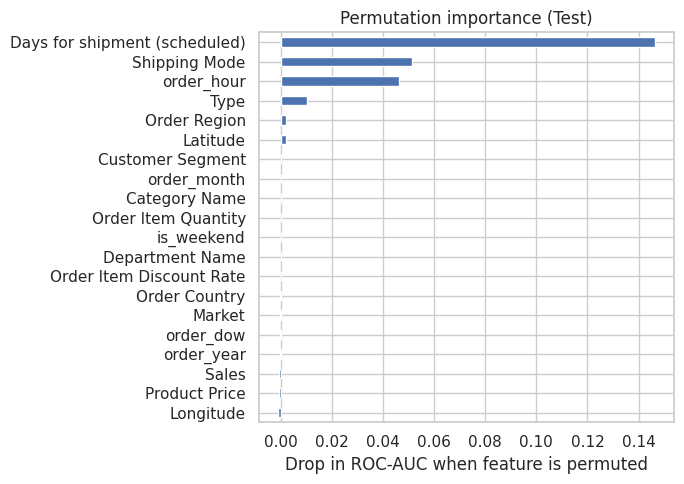

,importance
Days for shipment (scheduled),0.146486
Shipping Mode,0.051180
order_hour,0.046208
Type,0.010356
Order Region,0.001969
Latitude,0.001898
Customer Segment,0.000174
order_month,0.000157


In [ ]:
# Permutation importance บน Test (ใช้เพื่อ "ตีความ" โมเดลที่เลือกแล้ว ไม่ใช่เพื่อเลือกโมเดล)
fs_final = registry[FINAL_NAME][1]
n_, c_ = FEATURE_SETS[fs_final]
sub = X_test[n_ + c_].sample(15000, random_state=RANDOM_STATE)
pi = permutation_importance(final_model, sub, y_test.loc[sub.index], scoring='roc_auc',
                            n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=n_ + c_).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
imp.plot.barh(ax=ax); ax.set_xlabel('Drop in ROC-AUC when feature is permuted'); ax.set_title('Permutation importance (Test)')
plt.tight_layout(); plt.show()
display(imp.sort_values(ascending=False).head(8).to_frame('importance'))

* Permutation importance : สลับค่าของฟีเจอร์ทีละตัว แล้วดูว่า ROC-AUC ของโมเดลสุดท้าย (HistGB default B) ลดลงเท่าไร ยิ่งลดมาก = โมเดลพึ่งฟีเจอร์นั้นมาก
* โมเดลทำนายการล่าช้าโดยอาศัย 3 ฟีเจอร์เป็นหลัก ได้แก่ Days for shipment (scheduled), Shipping Mode และ order_hour ส่วนฟีเจอร์อื่นแทบไม่มีผลต่อการทำนาย ซึ่งสอดคล้องกับ ROC-AUC ที่อยู่ราว 0.77 และ recall ของคลาส late ที่ราว 0.60 การจะให้โมเดลดีขึ้นจึงควรสร้างฟีเจอร์ใหม่ที่มีลักษณะคล้าย order_hour

In [ ]:
# Error analysis: โมเดลพลาดตรงไหน ?
err = pd.DataFrame({'mode': X_test['Shipping Mode'].values, 'y': y_test.values, 'pred': final_pred})
err['wrong'] = err['y'] != err['pred']
by_mode = err.groupby('mode').apply(lambda d: pd.Series({
    'n': len(d), 'late_rate_true': d['y'].mean(), 'pred_late_rate': d['pred'].mean(),
    'error_rate': d['wrong'].mean(),
    'recall_late': ((d['pred'] == 1) & (d['y'] == 1)).sum() / max((d['y'] == 1).sum(), 1),
}))
by_mode['n'] = by_mode['n'].astype(int)
display(by_mode)

fn_share = err[(err['y'] == 1) & (err['pred'] == 0)]['mode'].value_counts(normalize=True)
print('สัดส่วน False Negative (ล่าช้าจริงแต่ทำนายไม่ล่าช้า) แยกตาม Shipping Mode:')
display(fn_share.to_frame('share_of_FN'))

,n,late_rate_true,pred_late_rate,error_rate,recall_late
mode,,,,,
First Class,5631,0.955781,0.999467,0.044752,0.999443
Same Day,1976,0.438259,0.457996,0.019737,1.000000
Second Class,7052,0.774674,0.998015,0.227028,0.997620
Standard Class,21317,0.372613,0.010414,0.376179,0.009190


สัดส่วน False Negative (ล่าช้าจริงแต่ทำนายไม่ล่าช้า) แยกตาม Shipping Mode:


,share_of_FN
mode,
Standard Class,0.997971
Second Class,0.001648
First Class,0.000380


* ความผิดพลาดเกือบทั้งหมดมาจาก Standard Class โมเดลทายว่าล่าช้าเพียง 1.0% ของออเดอร์ในโหมดนี้ ทั้งที่ล่าช้าจริง 37.3% ทำให้ recall เหลือ 0.009 และ FN 99.8% มาจากโหมดนี้ ส่วนอีก 3 โหมดจับออเดอร์ล่าช้าได้เกือบครบ (recall ≥ 0.998)

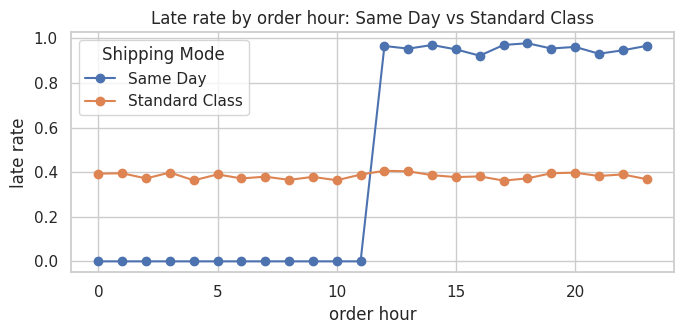

In [ ]:
# order_hour มีความสำคัญสูง — สัญญาณนี้อยู่ที่ไหน? (ใช้เฉพาะข้อมูล train)
tmp = X_train[['Shipping Mode', 'order_hour']].assign(late=y_train.values)
hr = (tmp[tmp['Shipping Mode'].isin(['Same Day', 'Standard Class'])]
      .groupby(['Shipping Mode', 'order_hour'])['late'].mean().unstack(0))
fig, ax = plt.subplots(figsize=(7, 3.5))
hr.plot(ax=ax, marker='o'); ax.set_ylabel('late rate'); ax.set_xlabel('order hour')
ax.set_title('Late rate by order hour: Same Day vs Standard Class'); plt.tight_layout(); plt.show()

* order_hour ให้สัญญาณเฉพาะใน Same Day (สั่งก่อนเที่ยงไม่ล่าช้า สั่งหลังเที่ยงล่าช้าเกือบหมด) ส่วนใน Standard Class late rate คงที่ ~0.38 ทุกชั่วโมง จึงเป็นสาเหตุที่ปัญหา recall กระจุกอยู่ที่ Standard Class

## 8. Interpretation, Model Selection และ Trade-offs

### 8.1 โมเดลที่เลือกและเหตุผล
**โมเดลสุดท้าย: HistGradientBoosting + ฟีเจอร์ชุด B (ค่าเริ่มต้น)** — เลือกจากผล Validation (CV) เท่านั้น ด้วยกติกาที่กำหนดไว้ล่วงหน้า: เลือกโมเดลที่ ROC-AUC สูงสุด และถ้าห่างกันไม่เกิน 1 SD ให้เลือกตัวที่ง่าย/เร็วกว่า

| โมเดล | CV ROC-AUC | Test ROC-AUC | หมายเหตุ |
|---|---|---|---|
| Dummy | 0.500 | – | baseline ต่ำสุด |
| LogReg: Shipping Mode only | 0.726 | – | baseline เชิงกฎ |
| LogReg (B) | 0.740 | – | ตีความง่ายแต่จับ interaction ไม่ได้ |
| RandomForest (B) | 0.764 | – | ใกล้เคียง HGB แต่ใช้เวลา CV นานกว่า ~5 เท่า (≈104 วินาที vs ≈22 วินาที สำหรับ 5 fold) |
| HistGB default (A) — โมเดลเดิม | 0.735 | – | ก่อนปรับปรุง |
| **HistGB default (B)** | **0.766** | **0.774** | **โมเดลสุดท้าย** |
| HistGB tuned (B) | 0.768 | – | ต่างจาก default < 1 SD |

Test Set ใช้ประเมินเฉพาะโมเดลสุดท้ายเพียงครั้งเดียว (โมเดลอื่นจึงไม่มีค่า Test) ผล CV กับ Test สอดคล้องกัน (0.766 vs 0.774) แสดงว่าไม่มีสัญญาณ overfit ต่อ validation และการแบ่งแบบ Group ทำงานได้ตามต้องการ

### 8.2 สรุปผลการทดลองปรับปรุง (ก่อน–หลัง)
Exp 1 : Feature Engineering/Selection (A→B)
  * HGB CV AUC เพิ่มจาก 0.735 เป็น 0.766 (+0.032) ได้ผลชัดเจน เพราะเกิน SD ของ CV (≈0.003–0.004) ฟีเจอร์ที่ตัดออก (City/State/ZIP) เป็น noise
  * ฟีเจอร์ที่เพิ่ม มีสัญญาณจริง โดยโมเดลไม่เชิงเส้นได้ประโยชน์มากกว่า (RF +0.033, HGB +0.032) เทียบกับ LogReg (+0.007) แปลว่ามี interaction ระหว่างฟีเจอร์

Exp 2: Hyperparameter Tuning CV AUC
  * เปลี่ยนจาก 0.7665 เป็น 0.7683 ซึ่งแทบไม่ต่างกัน (ต่างแค่ 0.0018 ซึ่งน้อยกว่าความผันผวนระหว่าง fold ≈0.003–0.004)
  * แปลว่าโมเดลเรียนรู้ได้เต็มที่ตามข้อมูลที่มีแล้ว ข้อจำกัดอยู่ที่ข้อมูล ไม่ใช่ค่าพารามิเตอร์

Exp 3: Class weight / Threshold

ทดลองปรับน้ำหนักคลาสและเกณฑ์ตัดสิน เพื่อดูว่าจะช่วยให้ทายคลาส "ล่าช้า" ได้ดีขึ้นไหม ผลคือ
  * F1-macro แทบไม่เปลี่ยน (ทุกแบบอยู่ที่ 0.7149–0.7150) เพราะข้อมูลสองคลาสมีสัดส่วนใกล้เคียงกันอยู่แล้ว (55/45) การถ่วงน้ำหนักจึงไม่จำเป็น
  * เมื่อขยับ threshold ผลก็แทบไม่เปลี่ยนตาม (เส้นโค้งแบนมาก) โดย Recall ของคลาส "ล่าช้า" ยังคงอยู่ที่ประมาณ 0.58–0.59
  * แปลว่าปัญหาไม่ได้อยู่ที่วิธีตัดสินใจของโมเดล แต่อยู่ที่ข้อมูลที่มีสัญญาณแยกสองคลาสได้เท่านี้
### 8.3 โมเดลเรียนรู้อะไร? (Error Analysis)
* Permutation importance สูงสุด 3 อันดับแรกคือ Days for shipment (scheduled), Shipping Mode และ order_hour โดยสองตัวแรกบอกข้อมูลเดียวกัน คือระดับการขนส่ง แปลว่าโมเดลทายว่าส่งล่าช้าหรือไม่จาก "แผนการจัดส่ง" เป็นหลัก
* จากตาราง Error Analysis โมเดลทำงานเหมือนกฎง่าย ๆ ที่ใช้แค่ประเภทการจัดส่ง       
  * ถ้าเป็น First Class หรือ Second Class โมเดลจะทายว่า "ล่าช้า" เกือบทุกครั้ง (จับพัสดุที่ล่าช้าจริงได้ประมาณ 99.8%)
  * ถ้าเป็น Standard Class โมเดลจะทายว่า "ไม่ล่าช้า" เกือบทั้งหมด (จับพัสดุที่ล่าช้าจริงได้เพียงประมาณ 1%)  
  * แปลผล : โมเดลแทบไม่ได้แยกแยะพัสดุทีละชิ้น แต่ตัดสินจากประเภทการส่งอย่างเดียว ซึ่งสอดคล้องกับผล Permutation importance ที่ Shipping Mode และ Days for shipment เป็นฟีเจอร์ที่สำคัญที่สุด และอธิบายได้ว่าทำไม Recall ของคลาส "ล่าช้า" โดยรวมจึงติดอยู่ที่ประมาณ 0.58–0.59 ไม่ว่าจะปรับโมเดลหรือ threshold อย่างไร
* False Negative ≈ 99.8% มาจาก Standard Class ซึ่งเป็นสัดส่วนประมาณ 60% ของออเดอร์ และล่าช้าจริงประมาณ 38% ในข้อมูลไม่มีฟีเจอร์ไหนแยกได้ว่าออเดอร์ Standard ชิ้นไหนจะล่าช้าหรือไม่ล่าช้า อีกทั้งกราฟ order hour ของ Standard Class แบนราบ คือสั่งตอนไหนโอกาสล่าช้าก็ใกล้เคียงกัน โมเดลจึงทายว่า "ไม่ล่าช้า" ทั้งกลุ่ม ทำให้พลาดแทบทุกชิ้นที่ล่าช้าจริง
* ส่วนที่ฟีเจอร์ชุด B เพิ่มให้คือ Same Day: ออเดอร์ที่สั่ง ก่อนเที่ยง ไม่ล่าช้าเลย ส่วน หลังเที่ยงล่าช้า ≈ 96% (error rate ของ Same Day เหลือเพียง ≈ 2.0%) ซึ่งเป็นสาเหตุที่ order_hour สำคัญ

### 8.4 ข้อจำกัด (Limitations)
1. ข้อมูลที่มีไม่ครอบคลุมสาเหตุจริงของการล่าช้า เช่น บริษัทขนส่ง สภาพอากาศ หรือความแออัดของคลังสินค้า โมเดลจึงเก่งได้แค่ระดับหนึ่ง (ROC-AUC ≈ 0.77) โดยเฉพาะกลุ่ม Standard Class
2. กฎ "Same Day ก่อน/หลังเที่ยง" ชัดเจนผิดธรรมชาติ (96% vs 0%) น่าจะมาจากวิธีสร้างข้อมูลหรือกฎ cut-off ของบริษัท ควรยืนยันกับเจ้าของข้อมูลก่อนนำไปใช้จริง
3. การแบ่งข้อมูลแบบสุ่มตามกลุ่ม ยังไม่ได้พิสูจน์ว่าทายอนาคตได้จริง ควรทดสอบเพิ่มโดยแบ่งตามช่วงเวลา และยังไม่ได้แยกตามลูกค้า ลูกค้าคนเดียวกันจึงอาจอยู่ทั้งชุด train และ test
4. คะแนนของโมเดลอันดับต้น ๆ (HGB / RF / tuned) ต่างกันน้อยจนอยู่ในช่วงความคลาดเคลื่อนของ CV จึงบอกไม่ได้แน่ว่าตัวไหนดีกว่ากัน
5. ยังไม่ได้ปรับเทียบความน่าจะเป็น (calibration) จึงไม่ควรตีความ predict_proba เป็นความเสี่ยงที่แท้จริงโดยตรง

### 8.5 Trade-offs และข้อเสนอแนะการใช้งาน
* Precision vs Recall : เมื่อโมเดลทายว่า "ล่าช้า" มักจะถูก (Precision ≈ 0.85 บน Test) แต่จับพัสดุที่ล่าช้าจริงได้แค่ราว 60% (Recall ≈ 0.60) จึงเหมาะเป็น ระบบเตือนที่เชื่อถือได้สูง สำหรับออเดอร์ First/Second Class และ Same Day หลังเที่ยง มากกว่าจะใช้ "คัดกรองให้ครบทุกออเดอร์ที่จะล่าช้า"
* ความซับซ้อน vs ประสิทธิภาพ : HGB ดีกว่า LogReg ≈ 0.03 AUC และเร็วกว่า RF มาก จึงคุ้มค่ากว่า แต่ตีความยากกว่า (ใช้ permutation importance ช่วย)
* ข้อเสนอเพื่อพัฒนาต่อ : เก็บข้อมูลผู้ให้บริการขนส่ง/สภาพอากาศ/ภาระคลัง, ทดสอบแบบแบ่งตามเวลา, เพิ่ม calibration, และลองโมเดลสำหรับ Standard Class โดยเฉพาะ